# 03 · Full OSV-5M Dataset Distribution Audit

Before designing the retrieval gallery, we audit the global distribution of the full official OSV-5M `train`, official `test`, and our initial 2,000-image gallery using complete pinned metadata (no image downloads required), alongside 25 km neighborhood coverage of `pilot_dev`.

Pinned `train.csv` contains 4,894,684 rows (the CVPR datasheet cites 4,894,685); all statistics here reflect exact rows in the pinned CSV.


In [3]:
import hashlib
import json
import subprocess
import sys
import zipfile
from pathlib import Path

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "scripts/audit_distribution.py").is_file()), None)
if root is None:
    target = Path("/content/distribution-audit")
    uploads = list(Path("/content").rglob("distribution_audit_upload.zip"))
    if len(uploads) != 1:
        raise FileNotFoundError("Upload distribution_audit_upload.zip from the SSD with VS Code.")
    target.mkdir(exist_ok=True)
    with zipfile.ZipFile(uploads[0]) as z:
        for member in z.infolist():
            if not (target / member.filename).resolve().is_relative_to(target.resolve()):
                raise ValueError("Unexpected ZIP member name")
        z.extractall(target)
    root = target
results = root / "results/distribution_audit"
print(root)

/content/distribution-audit


In [4]:
if not (results / "summary.json").is_file():
    metadata = root / "data/raw/osv5m-test.csv"
    if not metadata.exists():
        url = ("https://huggingface.co/datasets/osv5m/osv5m/resolve/"
               "cff33609b56b54d8743b7ee7a416eb8433e9a681/test.csv")
        partial = metadata.with_suffix(".part")
        subprocess.run(["curl", "-fLsS", "--retry", "2", url, "-o", str(partial)], check=True)
        partial.replace(metadata)
    command = [sys.executable, "-B", "-u", str(root / "scripts/audit_distribution.py")]
    with subprocess.Popen(command, cwd=root, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait():
            raise subprocess.CalledProcessError(process.returncode, command)
summary = json.loads((results / "summary.json").read_text())
display(summary)

Full test metadata verified; scanning all train metadata ranges.
Full train audit: 8/116 byte ranges, 342,119 rows
Full train audit: 16/116 byte ranges, 694,870 rows
Full train audit: 24/116 byte ranges, 1,036,961 rows
Full train audit: 32/116 byte ranges, 1,361,192 rows
Full train audit: 40/116 byte ranges, 1,696,975 rows
Full train audit: 48/116 byte ranges, 2,046,418 rows
Full train audit: 56/116 byte ranges, 2,386,756 rows
Full train audit: 64/116 byte ranges, 2,727,790 rows
Full train audit: 72/116 byte ranges, 3,068,350 rows
Full train audit: 80/116 byte ranges, 3,400,014 rows
Full train audit: 88/116 byte ranges, 3,724,418 rows
Full train audit: 96/116 byte ranges, 4,067,850 rows
Full train audit: 104/116 byte ranges, 4,401,662 rows
Full train audit: 112/116 byte ranges, 4,729,157 rows
Full train audit: 116/116 byte ranges, 4,894,684 rows
{"revision": "cff33609b56b54d8743b7ee7a416eb8433e9a681", "grid_degrees": 2, "coverage_radius_km": 25.0, "paper_train_n": 4894685, "splits": {"

{'revision': 'cff33609b56b54d8743b7ee7a416eb8433e9a681',
 'grid_degrees': 2,
 'coverage_radius_km': 25.0,
 'paper_train_n': 4894685,
 'splits': {'train': {'n': 4894684,
   'country_codes': 222,
   'top_countries': [['US', 1218664],
    ['DE', 272282],
    ['FR', 242074],
    ['RU', 222351],
    ['JP', 209205],
    ['AU', 162138],
    ['BR', 140599],
    ['GB', 137648],
    ['SE', 131816],
    ['IT', 115084],
    ['PL', 106124],
    ['ES', 96508]],
   'regions': {'paris_area': 13388, 'lyon_area': 6849, 'toulouse_area': 13082},
   'covered_pilot': 18},
  'test': {'n': 210122,
   'country_codes': 219,
   'top_countries': [['US', 23875],
    ['RU', 14984],
    ['AU', 11052],
    ['BR', 10425],
    ['CA', 9580],
    ['IN', 6525],
    ['MX', 4759],
    ['CN', 4404],
    ['AR', 4260],
    ['KZ', 3883],
    ['TR', 3537],
    ['CD', 3270]],
   'regions': {'toulouse_area': 29, 'paris_area': 43, 'lyon_area': 23},
   'covered_pilot': 18},
  'gallery': {'n': 2000,
   'country_codes': 59,
   'top_co

## Global Distribution

Cell color shows each `2° × 2°` cell's share of images in the respective split on a shared scale (note that surface area per `2° × 2°` cell varies with latitude).


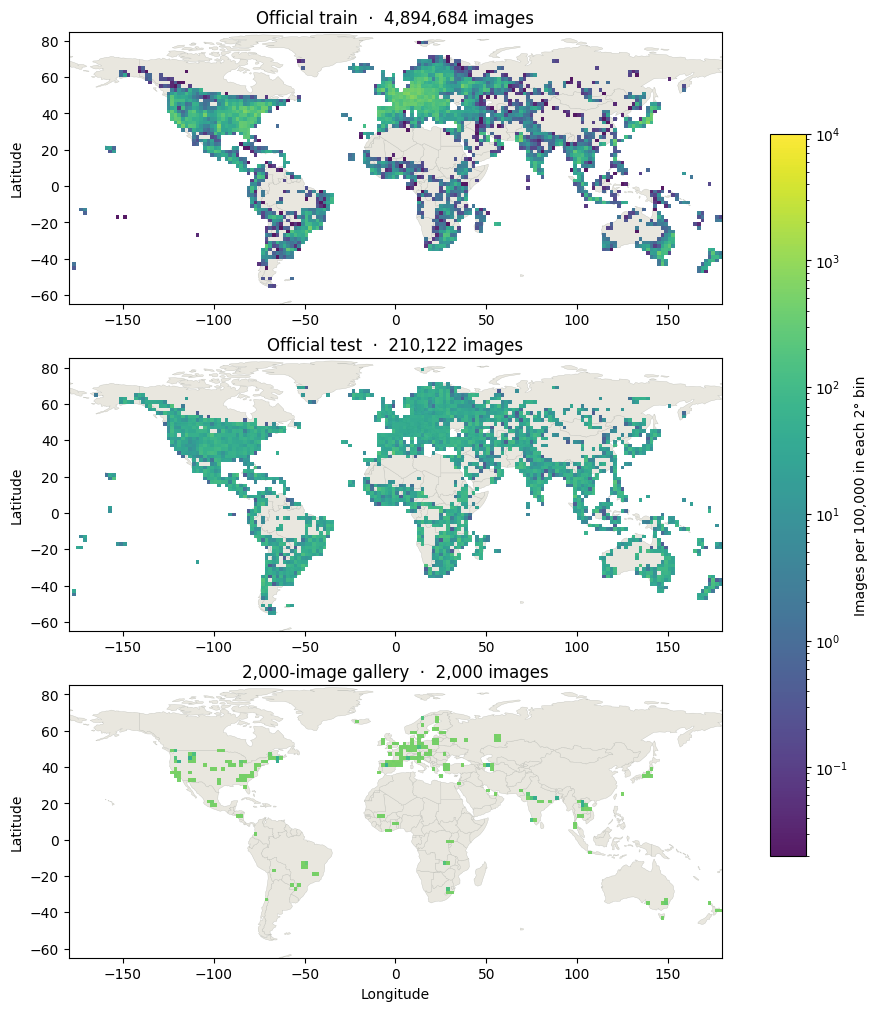

In [5]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm

splits = [("train", "Official train"), ("test", "Official test"), ("gallery", "2,000-image gallery")]
rows = list(csv.DictReader((results / "grid_2deg.csv").open()))
data = json.loads((root / "data/raw/ne_110m_admin_0_countries.geojson").read_text())
outlines = [polygon[0] for f in data["features"] for g in [f["geometry"]]
            for polygon in (g["coordinates"] if g["type"]=="MultiPolygon" else [g["coordinates"]])]
fig, axes = plt.subplots(3, 1, figsize=(11, 10), layout="constrained")
for ax, (split, title) in zip(axes, splits):
    grid = np.zeros((90, 180))
    n = summary["splits"][split]["n"]
    for row in rows:
        grid[(int(row["south"])+90)//2, (int(row["west"])+180)//2] = int(row[split]) * 1e5 / n
    ax.add_collection(PolyCollection(outlines, facecolor="#e9e7df", edgecolor="#bdbeb7", linewidth=.25))
    mesh = ax.pcolormesh(np.arange(-180,181,2), np.arange(-90,91,2), np.ma.masked_equal(grid, 0),
                         cmap="viridis", norm=LogNorm(vmin=.02, vmax=10000), alpha=.9)
    ax.set(title=f"{title}  ·  {n:,} images", xlim=(-180, 180), ylim=(-65, 85),
           ylabel="Latitude", aspect="equal")
axes[-1].set_xlabel("Longitude")
fig.colorbar(mesh, ax=axes, shrink=.78, label="Images per 100,000 in each 2° bin")
plt.show()

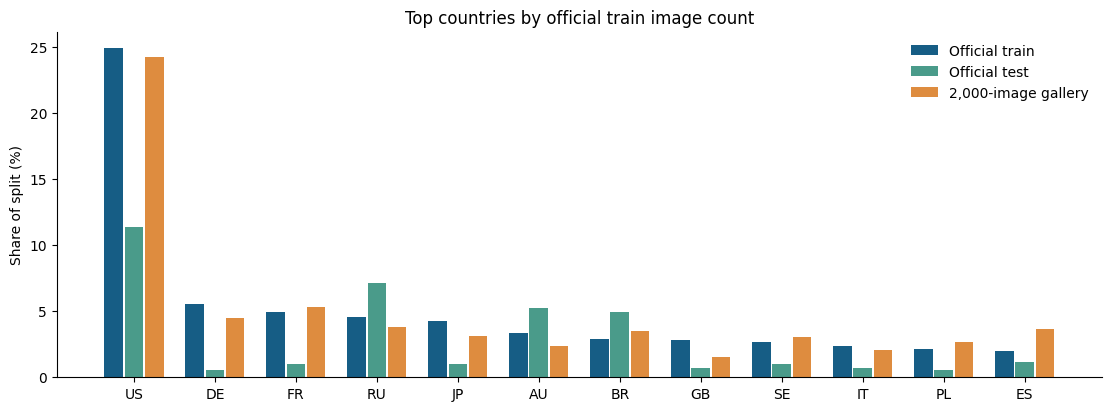

In [6]:
countries = list(csv.DictReader((results / "countries.csv").open()))
top = sorted(countries, key=lambda row: int(row["train"]), reverse=True)[:12]
x = np.arange(len(top))
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for i, ((split,label),color) in enumerate(zip(splits, ["#165d85","#4a9b8a","#de8c3f"])):
    n = summary["splits"][split]["n"]
    ax.bar(x + (i-1)*.25, [100*int(r[split])/n for r in top], width=.23, label=label, color=color)
ax.set(xticks=x, xticklabels=[r["country"] for r in top], ylabel="Share of split (%)",
       title="Top countries by official train image count")
ax.legend(frameon=False)
ax.spines[["top","right"]].set_visible(False)
plt.show()

In [7]:
cover = list(csv.DictReader((results / "pilot_coverage.csv").open()))
print("25 km reference coverage by source and region")
print(f"{'Source':<10} {'Region':<16} {'Official train':>15} {'2k gallery':>12}")
for provider in ("osv5m","panoramax"):
    for region in ("paris_area","lyon_area","toulouse_area"):
        matching=[r for r in cover if r["source"]==provider and r["region"]==region]
        a=sum(int(r["train_n"])>0 for r in matching)
        b=sum(int(r["gallery_n"])>0 for r in matching)
        print(f"{provider:<10} {region:<16} {a:>12}/{len(matching):<2} {b:>9}/{len(matching):<2}")
print("Per-query picture/sequence counts and nearest references: pilot_coverage.csv")

25 km reference coverage by source and region
Source     Region            Official train   2k gallery
osv5m      paris_area                  3/3          0/3 
osv5m      lyon_area                   3/3          1/3 
osv5m      toulouse_area               3/3          0/3 
panoramax  paris_area                  3/3          0/3 
panoramax  lyon_area                   3/3          1/3 
panoramax  toulouse_area               3/3          0/3 
Per-query picture/sequence counts and nearest references: pilot_coverage.csv


## Key Findings

- Full `train` covers 222 country/territory codes, official `test` covers 219, and the 2,000-image gallery covers 59. The US accounts for 24.90%, 11.36%, and 24.20%, respectively; France accounts for 4.95%, 0.97%, and 5.30%.
- Full `train` covers **18/18** French `pilot_dev` images within 25 km (734 to 4,175 neighbors per query, median nearest neighbor 1.09 km), whereas the 2,000-image gallery covers only **2/18** (both near Lyon).
- Those 16 missing hits occurred during small-gallery subsampling — motivating the coordinate-only coverage simulation and 25k coverage-first gallery in Notebook 04.


In [8]:
if root == Path("/content/distribution-audit"):
    archive = Path("/content/osv5m-distribution-audit.zip")
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as z:
        for name in ("countries.csv","grid_2deg.csv","pilot_coverage.csv","summary.json"):
            z.write(results / name, name)
    print(archive)
else:
    print(results)

/content/osv5m-distribution-audit.zip
